# CSD402 Deep Learning — Capstone Project (CA3)
## Option A: Multi-Stage Visual Quality System (CNN + GAN)

**Objective.** Build an end-to-end visual inspection system for a chosen domain and determine, on a real held-out test set, whether GAN-based augmentation of an under-represented class improves minority-class recall over a non-augmented baseline.

**Units covered.** Unit II (Convolutional Neural Networks, data augmentation, transfer learning), Unit IV (Generative Adversarial Networks), Unit VI (explainability through Grad-CAM).

**Workflow of this notebook.**

| Section | Content |
|---|---|
| 1 | Configuration |
| 2 | Data preparation and leakage-safe split |
| 3 | Evaluation utilities |
| 4 | Classifier architectures: from scratch and pretrained |
| 5 | Training procedure and Stage 1 experiments |
| 6 | Stage 2: DCGAN for minority-class augmentation |
| 7 | Validation comparison |
| 8 | Final evaluation on the test set |
| 9 | Grad-CAM explainability |
| 10 | Required analysis for the technical report |

Cells marked **Task** must be completed or extended as part of the project.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### Environment

Install the required packages once (Google Colab already provides most of them):

```
pip install torch torchvision scikit-learn pandas matplotlib pillow
```
A GPU runtime is recommended (Colab: *Runtime → Change runtime type → GPU*).

In [2]:
import os, json, random, time, copy
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from torchvision.utils import save_image, make_grid

from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix, f1_score,
                             recall_score, precision_score, average_precision_score)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

print("Device:", DEVICE)

Device: cuda


## 1. Configuration

The dataset must be arranged with one folder per class:

```
data/raw/good/img001.jpg
data/raw/defect/img002.jpg
```

Suitable public datasets include MVTec AD, NEU Surface Defect, Kaggle casting-product defects and PlantVillage. `MINORITY_KEEP` deliberately reduces the minority class **in the training split only**, so that the imbalance is controlled and documented; validation and test sets retain the natural distribution.

In [3]:
DATA_ROOT      = "/content/drive/MyDrive/DL_CA3_Dataset/defect_dataset"     # one sub-folder per class
MINORITY       = "dent"       # name of the under-represented class folder
MINORITY_KEEP  = 0.50         # Change default to 0.50 (~35 real minority training images per seed)
IMG_SIZE       = 224
BATCH_SIZE     = 32
EPOCHS         = 20
PATIENCE       = 5              # early stopping on validation macro-F1
USE_PRETRAINED = True           # download ImageNet weights for the transfer-learning model
SEED           = 42

GAN_EPOCHS     = 300
N_SYNTHETIC    = 500

# Configure persistent Google Drive path for all outputs
OUT = Path("/content/drive/MyDrive/DL_CA3_Dataset/outputs_option_a")
OUT.mkdir(parents=True, exist_ok=True)

set_seed(SEED)

In [4]:
from pathlib import Path

DATA_ROOT = Path("/content/drive/MyDrive/DL_CA3_Dataset/defect_dataset")

extensions = {".jpg", ".jpeg", ".png", ".bmp"}

counts = {}

for folder in DATA_ROOT.iterdir():
    if folder.is_dir():
        count = sum(
            1 for f in folder.rglob("*")
            if f.is_file() and f.suffix.lower() in extensions
        )
        counts[folder.name] = count

for name, count in sorted(counts.items(), key=lambda x: x[1]):
    print(f"{name}: {count}")

print("\nMinority class:", min(counts, key=counts.get))

mixed_defects: 100
flash: 100
cold_shut: 100
crack: 100
ok: 100
dent: 100
inclusion: 100
pinhole: 100
porosity: 100
scratch: 100
surface_roughness: 100
shrinkage: 100

Minority class: mixed_defects


## 2. Data preparation and leakage-safe split

**Principle: split first, then fit anything that learns from data on the training split only.**

The split is performed once, stratified by class, and saved to disk so that every experiment uses identical partitions.

| Split | Purpose |
|---|---|
| Train (70%) | Learning model weights; training the GAN |
| Validation (15%) | All decisions: architecture, epochs, learning rate, threshold |
| Test (15%) | A single final evaluation, reported once |

Typical sources of leakage in this option: training the GAN on images that later appear in validation or test; near-duplicate images of the same object across splits; selecting the epoch with the best *test* score.

In [5]:
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp"}

def list_images(root):
    root = Path(root)
    classes = sorted(d.name for d in root.iterdir() if d.is_dir())
    items = [(str(p), ci) for ci, c in enumerate(classes)
             for p in sorted((root / c).rglob("*")) if p.suffix.lower() in IMG_EXT]
    return items, classes

items, CLASSES = list_images(DATA_ROOT)
labels = [l for _, l in items]
MIN_IDX = CLASSES.index(MINORITY)

idx = np.arange(len(items))
tr_idx, tmp_idx = train_test_split(idx, test_size=0.30, stratify=labels, random_state=SEED)
va_idx, te_idx = train_test_split(tmp_idx, test_size=0.50, stratify=np.array(labels)[tmp_idx], random_state=SEED)
assert not (set(tr_idx) & set(va_idx) or set(tr_idx) & set(te_idx) or set(va_idx) & set(te_idx)), "Leakage"

train_items = [items[i] for i in tr_idx]
val_items   = [items[i] for i in va_idx]
test_items  = [items[i] for i in te_idx]

# Controlled imbalance: reduce the minority class in TRAIN only
rng = random.Random(SEED)
mins = [x for x in train_items if x[1] == MIN_IDX]
keep = rng.sample(mins, max(1, int(len(mins) * MINORITY_KEEP)))
train_items = [x for x in train_items if x[1] != MIN_IDX] + keep

json.dump({"classes": CLASSES, "train": train_items, "val": val_items, "test": test_items},
          open(OUT / "split.json", "w"))

counts = pd.DataFrame({s: pd.Series([CLASSES[l] for _, l in it]).value_counts()
                       for s, it in [("train", train_items), ("val", val_items), ("test", test_items)]})
counts

,train,val,test
cold_shut,70,15,15
crack,70,15,15
dent,35,15,15
flash,70,15,15
inclusion,70,15,15
mixed_defects,70,15,15
ok,70,15,15
pinhole,70,15,15
porosity,70,15,15
scratch,70,15,15


### 2.1 Pre-processing and augmentation

Augmentation is applied to the training split only. Each transformation should be justified for the domain: a vertical flip may be valid for fabric texture but not for printed documents; colour jitter may hide a colour-based defect.

Normalisation uses ImageNet statistics, which the pretrained backbone expects.

In [6]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(0.2, 0.2, 0.2),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

class ImageListDataset(Dataset):
    def __init__(self, items, tf): self.items, self.tf = items, tf
    def __len__(self): return len(self.items)
    def __getitem__(self, i):
        p, y = self.items[i]
        return self.tf(Image.open(p).convert("RGB")), y

def loader(items, tf, shuffle):
    return DataLoader(ImageListDataset(items, tf), batch_size=BATCH_SIZE, shuffle=shuffle, num_workers=2)

val_loader, test_loader = loader(val_items, eval_tf, False), loader(test_items, eval_tf, False)

## 3. Evaluation utilities

Accuracy is not an adequate metric for an imbalanced problem: with a 95/5 class ratio, a classifier that always predicts the majority class achieves 95% accuracy and 0% minority recall. The following are reported throughout:

- per-class precision, recall and F1;
- **minority-class recall** (the headline metric of this option);
- macro-F1 (unweighted mean of per-class F1);
- PR-AUC (area under the precision–recall curve), which is informative under imbalance;
- the confusion matrix.

In [7]:
@torch.no_grad()
def predict(model, dl):
    model.eval()
    ys, probs, loss_sum = [], [], 0.0
    for x, y in dl:
        out = model(x.to(DEVICE)).cpu()
        loss_sum += F.cross_entropy(out, y, reduction="sum").item()
        ys.append(y); probs.append(out.softmax(1))
    y, p = torch.cat(ys).numpy(), torch.cat(probs).numpy()
    return y, p.argmax(1), p, loss_sum / len(y)

def summarise(y, yp, prob):
    onehot = np.eye(len(CLASSES))[y]
    return {"macro_f1": f1_score(y, yp, average="macro", zero_division=0),
            "minority_recall": recall_score(y, yp, labels=[MIN_IDX], average="macro", zero_division=0),
            "minority_precision": precision_score(y, yp, labels=[MIN_IDX], average="macro", zero_division=0),
            "minority_pr_auc": average_precision_score(onehot[:, MIN_IDX], prob[:, MIN_IDX]),
            "accuracy": float((y == yp).mean())}

def full_report(y, yp, title):
    print(title); print(classification_report(y, yp, target_names=CLASSES, digits=4, zero_division=0))
    cm = confusion_matrix(y, yp)
    fig, ax = plt.subplots(figsize=(4, 3.5)); ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(len(CLASSES)), CLASSES, rotation=45); ax.set_yticks(range(len(CLASSES)), CLASSES)
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)): ax.text(j, i, cm[i, j], ha="center", va="center")
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(title); plt.tight_layout(); plt.show()

def plot_history(hist, title):
    h = pd.DataFrame(hist)
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
    ax[0].plot(h.epoch, h.train_loss, label="train"); ax[0].plot(h.epoch, h.val_loss, label="validation")
    ax[0].set_title(f"{title}: loss"); ax[0].legend()
    ax[1].plot(h.epoch, h.val_macro_f1, label="val macro-F1"); ax[1].plot(h.epoch, h.val_min_recall, label="val minority recall")
    ax[1].set_title(f"{title}: validation metrics"); ax[1].legend()
    for a in ax: a.set_xlabel("epoch"); a.grid(alpha=.3)
    plt.tight_layout(); plt.show()

## 4. Classifier architectures

**Model 1 — CNN trained from scratch.** Four convolutional blocks (Conv–BN–ReLU ×2, MaxPool) followed by global average pooling, dropout and a linear classifier. This establishes what can be learned from the available data alone.

**Model 2 — Transfer learning (ResNet-18 pretrained on ImageNet).** Early convolutional layers learn generic features (edges, textures) that transfer across domains. Training proceeds in two phases:

1. **Feature extraction:** the backbone is frozen and only the new classification head is trained for a few epochs, so that the randomly initialised head does not destroy pretrained features with large gradients.
2. **Fine-tuning:** all layers are unfrozen and trained with a small learning rate under a cosine schedule.

The comparison between Model 1 and Model 2 is a required element of this option.

In [8]:
class SmallCNN(nn.Module):
    def __init__(self, n_classes):
        super().__init__()
        def block(i, o):
            return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(),
                                 nn.Conv2d(o, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(2))
        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128), block(128, 256))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(256, n_classes))
    def forward(self, x): return self.head(self.features(x))

def build_model(name):
    if name == "scratch":
        return SmallCNN(len(CLASSES))
    m = models.resnet18(weights="DEFAULT" if USE_PRETRAINED else None)
    m.fc = nn.Linear(m.fc.in_features, len(CLASSES))
    return m

def set_backbone_trainable(model, trainable):
    if isinstance(model, SmallCNN): return
    for p in model.parameters(): p.requires_grad = trainable
    for p in model.fc.parameters(): p.requires_grad = True

for n in ["scratch", "resnet18"]:
    print(f"{n:>9}: {sum(p.numel() for p in build_model(n).parameters()):,} parameters")

  scratch: 1,177,260 parameters
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 134MB/s]


 resnet18: 11,182,668 parameters


## 5. Training procedure

All experiments share one training function so that comparisons are controlled: same seed, epochs, optimiser, schedule and stopping rule.

- **Optimiser:** AdamW with weight decay (L2 regularisation decoupled from the adaptive update).
- **Schedule:** cosine annealing of the learning rate.
- **Model selection:** the checkpoint with the best **validation macro-F1** is kept; training stops after `PATIENCE` epochs without improvement (early stopping).
- **Class weights (optional):** the cross-entropy loss is weighted by inverse class frequency, $w_c = \frac{N}{K \cdot n_c}$, so that errors on the minority class cost more.

The training and validation curves produced by each run are required in the report, together with a diagnosis (overfitting, underfitting, instability, imbalance) and the remedy applied.

In [9]:
def train_classifier(model_name, train_items, lr=1e-3, freeze_epochs=3, class_weights=False, tag="run"):
    set_seed(SEED)
    model = build_model(model_name).to(DEVICE)
    train_dl = loader(train_items, train_tf, True)
    w = None
    if class_weights:
        cnt = np.bincount([l for _, l in train_items], minlength=len(CLASSES)).astype(float)
        w = torch.tensor(cnt.sum() / (len(CLASSES) * np.maximum(cnt, 1)), dtype=torch.float32, device=DEVICE)
    crit = nn.CrossEntropyLoss(weight=w)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)

    hist, best_f1, best_state, bad = [], -1, None, 0
    for ep in range(1, EPOCHS + 1):
        set_backbone_trainable(model, ep > freeze_epochs)
        model.train(); tl, n = 0.0, 0
        for x, y in train_dl:
            x, y = x.to(DEVICE), y.to(DEVICE)
            loss = crit(model(x), y)
            opt.zero_grad(); loss.backward(); opt.step()
            tl += loss.item() * len(y); n += len(y)
        sched.step()
        y, yp, p, vl = predict(model, val_loader)
        s = summarise(y, yp, p)
        hist.append({"epoch": ep, "train_loss": tl / n, "val_loss": vl,
                     "val_macro_f1": s["macro_f1"], "val_min_recall": s["minority_recall"]})
        print(f"[{tag}] epoch {ep:2d}  train_loss {tl/n:.4f}  val_loss {vl:.4f}  "
              f"val_macroF1 {s['macro_f1']:.4f}  val_minority_recall {s['minority_recall']:.4f}")
        if s["macro_f1"] > best_f1:
            best_f1, best_state, bad = s["macro_f1"], copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= PATIENCE: print("Early stopping."); break
    model.load_state_dict(best_state)
    torch.save(best_state, OUT / f"{tag}.pt")
    pd.DataFrame(hist).to_csv(OUT / f"{tag}_history.csv", index=False)
    plot_history(hist, tag)
    return model, hist

RESULTS = {}
def record(tag, model):
    y, yp, p, _ = predict(model, val_loader)
    RESULTS[tag] = summarise(y, yp, p)

### 5.1 Experiment 1 — From scratch versus transfer learning

In [ ]:
m_scratch, _ = train_classifier("scratch", train_items, lr=1e-3, freeze_epochs=0, tag="scratch")
record("scratch", m_scratch)

m_resnet, _ = train_classifier("resnet18", train_items, lr=1e-3,  freeze_epochs=3, tag="resnet18")
record("resnet18", m_resnet)

### 5.2 Experiment 2 — Conventional imbalance remedy (class-weighted loss)

A GAN is only worth its cost if it outperforms simple remedies. Class weighting (or random oversampling of the minority class) is therefore included as a second baseline.

In [ ]:
BEST_ARCH = "resnet18"     # Task: set to the architecture selected on validation in Experiment 1
m_cw, _ = train_classifier(BEST_ARCH, train_items, class_weights=True, tag=f"{BEST_ARCH}_classweights")
record(f"{BEST_ARCH}_classweights", m_cw)

## 6. Stage 2 — DCGAN for minority-class augmentation

A GAN consists of a generator $G$, mapping noise $z \sim \mathcal{N}(0, I)$ to images, and a discriminator $D$, estimating the probability that an image is real. They play the minimax game

$$\min_G \max_D \; \mathbb{E}_{x \sim p_{data}}[\log D(x)] + \mathbb{E}_{z}[\log(1 - D(G(z)))].$$

The implementation below follows the DCGAN design (strided transposed convolutions, batch normalisation, ReLU in $G$, LeakyReLU in $D$, $\mathcal{N}(0, 0.02)$ initialisation, Adam with $\beta_1 = 0.5$) and uses two stabilisation measures:

- **Non-saturating generator loss:** $G$ maximises $\log D(G(z))$ rather than minimising $\log(1 - D(G(z)))$, which gives stronger gradients early in training.
- **One-sided label smoothing:** real images are labelled 0.9 instead of 1.0, preventing an over-confident discriminator.

**Leakage control:** the GAN is trained exclusively on minority images from the **training split**. Validation and test images are never seen by the generator.

**Failure modes to monitor:** *mode collapse* (all samples look alike), and a discriminator whose loss falls towards zero while the generator loss rises (the discriminator has won and $G$ receives no useful gradient). Remedies include lowering the discriminator learning rate, spectral normalisation, and more aggressive augmentation of the real images.

In [ ]:
NZ = 100

class Generator(nn.Module):        # z (100) -> 3 x 64 x 64
    def __init__(self, ngf=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.ConvTranspose2d(NZ, ngf*8, 4, 1, 0, bias=False), nn.BatchNorm2d(ngf*8), nn.ReLU(True),
            nn.ConvTranspose2d(ngf*8, ngf*4, 4, 2, 1, bias=False), nn.BatchNorm2d(ngf*4), nn.ReLU(True),
            nn.ConvTranspose2d(ngf*4, ngf*2, 4, 2, 1, bias=False), nn.BatchNorm2d(ngf*2), nn.ReLU(True),
            nn.ConvTranspose2d(ngf*2, ngf, 4, 2, 1, bias=False), nn.BatchNorm2d(ngf), nn.ReLU(True),
            nn.ConvTranspose2d(ngf, 3, 4, 2, 1, bias=False), nn.Tanh())
    def forward(self, z): return self.net(z)

class Discriminator(nn.Module):    # 3 x 64 x 64 -> logit
    def __init__(self, ndf=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(3, ndf, 4, 2, 1, bias=False), nn.LeakyReLU(0.2, True),
            nn.Conv2d(ndf, ndf*2, 4, 2, 1, bias=False), nn.BatchNorm2d(ndf*2), nn.LeakyReLU(0.2, True),
            nn.Conv2d(ndf*2, ndf*4, 4, 2, 1, bias=False), nn.BatchNorm2d(ndf*4), nn.LeakyReLU(0.2, True),
            nn.Conv2d(ndf*4, ndf*8, 4, 2, 1, bias=False), nn.BatchNorm2d(ndf*8), nn.LeakyReLU(0.2, True),
            nn.Conv2d(ndf*8, 1, 4, 1, 0, bias=False))
    def forward(self, x): return self.net(x).view(-1)

def dcgan_init(m):
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)): nn.init.normal_(m.weight, 0.0, 0.02)
    elif isinstance(m, nn.BatchNorm2d): nn.init.normal_(m.weight, 1.0, 0.02); nn.init.zeros_(m.bias)

In [ ]:
set_seed(SEED)
gan_items = [x for x in train_items if x[1] == MIN_IDX]          # TRAIN minority only
print(f"GAN training images: {len(gan_items)}")
gan_tf = transforms.Compose([transforms.Resize((64, 64)), transforms.RandomHorizontalFlip(),
                             transforms.ToTensor(), transforms.Normalize([0.5]*3, [0.5]*3)])
gan_dl = DataLoader(ImageListDataset(gan_items, gan_tf), batch_size=min(32, len(gan_items)), shuffle=True)

G, D = Generator().to(DEVICE), Discriminator().to(DEVICE)
G.apply(dcgan_init); D.apply(dcgan_init)
optG = torch.optim.Adam(G.parameters(), lr=2e-4, betas=(0.5, 0.999))
optD = torch.optim.Adam(D.parameters(), lr=2e-4, betas=(0.5, 0.999))
bce = nn.BCEWithLogitsLoss()
fixed_z = torch.randn(64, NZ, 1, 1, device=DEVICE)

gan_hist = []
for ep in range(1, GAN_EPOCHS + 1):
    ld = lg = n = 0
    for real, _ in gan_dl:
        real = real.to(DEVICE); b = real.size(0)
        fake = G(torch.randn(b, NZ, 1, 1, device=DEVICE))
        lossD = bce(D(real), torch.full((b,), 0.9, device=DEVICE)) + bce(D(fake.detach()), torch.zeros(b, device=DEVICE))
        optD.zero_grad(); lossD.backward(); optD.step()
        lossG = bce(D(fake), torch.ones(b, device=DEVICE))
        optG.zero_grad(); lossG.backward(); optG.step()
        ld += lossD.item(); lg += lossG.item(); n += 1
    gan_hist.append({"epoch": ep, "loss_D": ld / n, "loss_G": lg / n})
    if ep % 50 == 0 or ep == GAN_EPOCHS:
        print(f"GAN epoch {ep}: loss_D {ld/n:.3f}  loss_G {lg/n:.3f}")

torch.save(G.state_dict(), OUT / "generator.pt")
h = pd.DataFrame(gan_hist)
plt.figure(figsize=(6, 3)); plt.plot(h.epoch, h.loss_D, label="discriminator"); plt.plot(h.epoch, h.loss_G, label="generator")
plt.xlabel("epoch"); plt.legend(); plt.title("GAN losses"); plt.grid(alpha=.3); plt.show()

### 6.1 Sample quality

The grid below is generated from fixed random noise and is **not curated**. Real minority images are shown alongside for comparison. Assess realism and diversity; identical-looking samples indicate mode collapse.

In [ ]:
G.eval()
with torch.no_grad():
    fake_grid = make_grid(G(fixed_z[:32]) * 0.5 + 0.5, nrow=8)
real_batch = torch.stack([gan_tf(Image.open(p).convert("RGB")) for p, _ in gan_items[:32]]) * 0.5 + 0.5
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].imshow(make_grid(real_batch, nrow=8).permute(1, 2, 0)); ax[0].set_title("Real (train minority)")
ax[1].imshow(fake_grid.permute(1, 2, 0).cpu()); ax[1].set_title("Generated (random, uncurated)")
for a in ax: a.axis("off")
plt.show()

SYN_DIR = OUT / "synthetic" / MINORITY; SYN_DIR.mkdir(parents=True, exist_ok=True)
with torch.no_grad():
    for i in range(N_SYNTHETIC):
        save_image(G(torch.randn(1, NZ, 1, 1, device=DEVICE)) * 0.5 + 0.5, SYN_DIR / f"syn_{i:04d}.png")
syn_items = [(str(p), MIN_IDX) for p in sorted(SYN_DIR.glob("*.png"))]
print(f"{len(syn_items)} synthetic images written to {SYN_DIR}")

### 6.2 Experiment 3 — Classifier trained with GAN-augmented data

Synthetic images are added to the **training split only**. All other settings are identical to the baseline, so any difference is attributable to the augmentation.

In [ ]:
m_gan, _ = train_classifier(BEST_ARCH, train_items + syn_items, tag=f"{BEST_ARCH}_gan")
record(f"{BEST_ARCH}_gan", m_gan)

## 7. Validation comparison

Model selection is performed here, on the validation split. The test set has not yet been used.

In [ ]:
val_table = pd.DataFrame(RESULTS).T.round(4)
val_table.to_csv(OUT / "validation_comparison.csv")
val_table

```markdown
### 7.1 Multi-Seed Execution Guide and Quality Protocol

To execute the rigorous, multi-seed statistical evaluation correctly, please follow this execution sequence:

1. **Run Setup & Configuration Cells:** Execute all cells from Section 1 (Configuration) through Section 3 (Evaluation Utilities).
2. **Skip Single-Seed Exploration (Optional):** You may safely skip the training cells in Sections 5 and 6 (such as `5badcfb9`, `8be3d18a`, `e4a5ca27`) to proceed directly to the multi-seed evaluation.
3. **Skip Deprecated Cell 31 (`9d9e6d5c`):** This is an obsolete multi-seed implementation.
4. **Run Active Multi-Seed Cell 32 (`b8db3832`):** This cell dynamically performs the 70/15/15 stratified partition split across 3 seeds:
   - **Configurable Imbalance (`MINORITY_KEEP = 0.50`):** Retains 50% of the minority class in training, giving approximately 35 real minority images per seed for GAN training.
   - **Robust GAN Checkpointing & Resuming (Every 10 Epochs):** Saves intermediate generator and discriminator state dicts, optimizer states, epoch counts, and JSON histories every 10 epochs. It securely resumes training after a Colab disconnection, isolated per seed.
   - **Quality Monitoring & Warnings:** Monitors G and D losses, saving generated sample grids to the Google Drive folder every 50 epochs. It prints automatic warnings for early signs of mode collapse or poor-quality generations.
```

In [ ]:
# =============================================================================
# DEPRECATED / OBSOLETE CELL
# =============================================================================
# This cell is an obsolete duplicate of the multi-seed implementation.
# All active multi-seed experiments are executed and processed cleanly in Cell 32 (b8db3832).
# Please do not run this cell.
# =============================================================================
print("This cell is deprecated. Please skip to Cell 32 (b8db3832) below.")

In [11]:
 import numpy as np
import pandas as pd
import json
import random
import copy
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from torchvision.utils import save_image, make_grid
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, recall_score, precision_score, average_precision_score
from PIL import Image
from pathlib import Path
import matplotlib.pyplot as plt

# --- 0. Setup and Self-Contained Configurations ---
if 'IMG_SIZE' not in globals():
    IMG_SIZE = 224
if 'BATCH_SIZE' not in globals():
    BATCH_SIZE = 32
if 'EPOCHS' not in globals():
    EPOCHS = 20
if 'PATIENCE' not in globals():
    PATIENCE = 5
if 'USE_PRETRAINED' not in globals():
    USE_PRETRAINED = True
if 'GAN_EPOCHS' not in globals():
    GAN_EPOCHS = 300
if 'N_SYNTHETIC' not in globals():
    N_SYNTHETIC = 500
if 'DEVICE' not in globals():
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if 'OUT' not in globals():
    OUT = Path("/content/drive/MyDrive/DL_CA3_Dataset/outputs_option_a")
if 'MINORITY' not in globals():
    MINORITY = "dent"
if 'DATA_ROOT' not in globals():
    DATA_ROOT = Path("/content/drive/MyDrive/DL_CA3_Dataset/defect_dataset")

OUT.mkdir(parents=True, exist_ok=True)

# Secure dataset reconstruction directly from DATA_ROOT to guarantee complete, un-downsampled list
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp"}
root_path = Path(DATA_ROOT)
CLASSES = sorted(d.name for d in root_path.iterdir() if d.is_dir())
items = [(str(p), ci) for ci, c in enumerate(CLASSES)
         for p in sorted((root_path / c).rglob("*")) if p.suffix.lower() in IMG_EXT]
labels = [l for _, l in items]
idx = np.arange(len(items))

MIN_IDX = CLASSES.index(MINORITY)
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
MINORITY_KEEP = 0.50

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(0.2, 0.2, 0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

class ImageListDataset(Dataset):
    def __init__(self, items, tf):
        self.items, self.tf = items, tf
    def __len__(self):
        return len(self.items)
    def __getitem__(self, i):
        p, y = self.items[i]
        return self.tf(Image.open(p).convert("RGB")), y

def loader(items, tf, shuffle):
    return DataLoader(ImageListDataset(items, tf), batch_size=BATCH_SIZE, shuffle=shuffle, num_workers=2)

if 'set_seed' not in globals():
    def set_seed(seed=42):
        random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

# Export exact, un-downsampled Seed 42 test split safely once
set_seed(42)
tr_idx_42, tmp_idx_42 = train_test_split(idx, test_size=0.30, stratify=labels, random_state=42)
va_idx_42, te_idx_42 = train_test_split(tmp_idx_42, test_size=0.50, stratify=np.array(labels)[tmp_idx_42], random_state=42)
test_items_42 = [items[i] for i in te_idx_42]
with open(OUT / "seed_42_test_split.json", "w") as f:
    json.dump({"test_items": test_items_42, "classes": CLASSES}, f)

# --- 1. Architectures ---
class SmallCNN(nn.Module):
    def __init__(self, n_classes):
        super().__init__()
        def block(i, o):
            return nn.Sequential(
                nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(),
                nn.Conv2d(o, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(),
                nn.MaxPool2d(2)
            )
        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128), block(128, 256))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(256, n_classes))
    def forward(self, x):
        return self.head(self.features(x))

def build_model(name):
    if name == "scratch":
        return SmallCNN(len(CLASSES))
    m = models.resnet18(weights="DEFAULT" if USE_PRETRAINED else None)
    m.fc = nn.Linear(m.fc.in_features, len(CLASSES))
    return m

def set_backbone_trainable(model, trainable):
    if isinstance(model, SmallCNN): return
    for p in model.parameters(): p.requires_grad = trainable
    for p in model.fc.parameters(): p.requires_grad = True

# --- 2. DCGAN Generator & Discriminator ---
NZ = 100
class Generator(nn.Module):
    def __init__(self, ngf=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.ConvTranspose2d(NZ, ngf*8, 4, 1, 0, bias=False), nn.BatchNorm2d(ngf*8), nn.ReLU(True),
            nn.ConvTranspose2d(ngf*8, ngf*4, 4, 2, 1, bias=False), nn.BatchNorm2d(ngf*4), nn.ReLU(True),
            nn.ConvTranspose2d(ngf*4, ngf*2, 4, 2, 1, bias=False), nn.BatchNorm2d(ngf*2), nn.ReLU(True),
            nn.ConvTranspose2d(ngf*2, ngf, 4, 2, 1, bias=False), nn.BatchNorm2d(ngf), nn.ReLU(True),
            nn.ConvTranspose2d(ngf, 3, 4, 2, 1, bias=False), nn.Tanh())
    def forward(self, z): return self.net(z)

class Discriminator(nn.Module):
    def __init__(self, ndf=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(3, ndf, 4, 2, 1, bias=False), nn.LeakyReLU(0.2, True),
            nn.Conv2d(ndf, ndf*2, 4, 2, 1, bias=False), nn.BatchNorm2d(ndf*2), nn.LeakyReLU(0.2, True),
            nn.Conv2d(ndf*2, ndf*4, 4, 2, 1, bias=False), nn.BatchNorm2d(ndf*4), nn.LeakyReLU(0.2, True),
            nn.Conv2d(ndf*4, ndf*8, 4, 2, 1, bias=False), nn.BatchNorm2d(ndf*8), nn.LeakyReLU(0.2, True),
            nn.Conv2d(ndf*8, 1, 4, 1, 0, bias=False))
    def forward(self, x): return self.net(x).view(-1)

def dcgan_init(m):
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)): nn.init.normal_(m.weight, 0.0, 0.02)
    elif isinstance(m, nn.BatchNorm2d): nn.init.normal_(m.weight, 1.0, 0.02); nn.init.zeros_(m.bias)

# --- 3. Evaluation Helpers ---
@torch.no_grad()
def predict(model, dl):
    model.eval()
    ys, probs, loss_sum = [], [], 0.0
    for x, y in dl:
        out = model(x.to(DEVICE)).cpu()
        loss_sum += F.cross_entropy(out, y, reduction="sum").item()
        ys.append(y); probs.append(out.softmax(1))
    y, p = torch.cat(ys).numpy(), torch.cat(probs).numpy()
    return y, p.argmax(1), p, loss_sum / len(y)

def summarise(y, yp, prob):
    onehot = np.eye(len(CLASSES))[y]
    return {
        "macro_f1": f1_score(y, yp, average="macro", zero_division=0),
        "minority_recall": recall_score(y, yp, labels=[MIN_IDX], average="macro", zero_division=0),
        "minority_precision": precision_score(y, yp, labels=[MIN_IDX], average="macro", zero_division=0),
        "minority_pr_auc": average_precision_score(onehot[:, MIN_IDX], prob[:, MIN_IDX]),
        "accuracy": float((y == yp).mean())
    }

def train_classifier(model_name, train_items, val_loader, lr=1e-3, freeze_epochs=3, class_weights=False, tag="run"):
    model = build_model(model_name).to(DEVICE)
    train_dl = loader(train_items, train_tf, True)
    w = None
    if class_weights:
        cnt = np.bincount([l for _, l in train_items], minlength=len(CLASSES)).astype(float)
        w = torch.tensor(cnt.sum() / (len(CLASSES) * np.maximum(cnt, 1)), dtype=torch.float32, device=DEVICE)
    crit = nn.CrossEntropyLoss(weight=w)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)

    hist, best_f1, best_state, bad = [], -1, None, 0
    for ep in range(1, EPOCHS + 1):
        set_backbone_trainable(model, ep > freeze_epochs)
        model.train(); tl, n = 0.0, 0
        for x, y in train_dl:
            x, y = x.to(DEVICE), y.to(DEVICE)
            loss = crit(model(x), y)
            opt.zero_grad(); loss.backward(); opt.step()
            tl += loss.item() * len(y); n += len(y)
        sched.step()
        y_v, yp_v, p_v, vl = predict(model, val_loader)
        s = summarise(y_v, yp_v, p_v)
        hist.append({
            "epoch": ep, "train_loss": tl / n, "val_loss": vl,
            "val_macro_f1": s["macro_f1"], "val_min_recall": s["minority_recall"]
        })
        if s["macro_f1"] > best_f1:
            best_f1, best_state, bad = s["macro_f1"], copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= PATIENCE: break
    model.load_state_dict(best_state)
    torch.save(best_state, OUT / f"{tag}.pt")
    return model, hist

# --- 4. Multi-Seed Experiment Run ---
seeds = [42, 101, 2023]
raw_csv_path = OUT / "multi_seed_results_raw.csv"

if raw_csv_path.exists():
    multi_seed_results = pd.read_csv(raw_csv_path).to_dict("records")
    print(f"Resumed session safely. Found {len(multi_seed_results)} already completed runs.")
else:
    multi_seed_results = []

def check_completed(seed, model_name):
    return any(r["seed"] == seed and r["model"] == model_name for r in multi_seed_results)

for seed in seeds:
    print(f"\n=== Starting Multi-Seed Run: Seed {seed} ===")
    set_seed(seed)

    tr_idx_s, tmp_idx_s = train_test_split(idx, test_size=0.30, stratify=labels, random_state=seed)
    va_idx_s, te_idx_s = train_test_split(tmp_idx_s, test_size=0.50, stratify=np.array(labels)[tmp_idx_s], random_state=seed)

    train_items_s = [items[i] for i in tr_idx_s]
    val_items_s = [items[i] for i in va_idx_s]
    test_items_s = [items[i] for i in te_idx_s]

    rng = random.Random(seed)
    mins_s = [x for x in train_items_s if x[1] == MIN_IDX]
    keep_s = rng.sample(mins_s, max(1, int(len(mins_s) * MINORITY_KEEP)))
    train_items_s = [x for x in train_items_s if x[1] != MIN_IDX] + keep_s

    val_loader_s = loader(val_items_s, eval_tf, False)

    seed_syn_dir = OUT / f"synthetic_seed_{seed}" / MINORITY
    seed_syn_dir.mkdir(parents=True, exist_ok=True)
    syn_items_s = [(str(p), MIN_IDX) for p in sorted(seed_syn_dir.glob("*.png"))]

    gan_ckpt_path = OUT / f"gan_checkpoint_seed_{seed}.pt"
    gan_history_path = OUT / f"gan_history_seed_{seed}.json"

    if len(syn_items_s) < N_SYNTHETIC:
        print(f"  -> Training/Resuming isolated DCGAN for Seed {seed}...")
        gan_items_s = [x for x in train_items_s if x[1] == MIN_IDX]
        print(f"     Available real minority training samples for GAN: {len(gan_items_s)}")
        gan_tf = transforms.Compose([transforms.Resize((64, 64)), transforms.RandomHorizontalFlip(),
                                     transforms.ToTensor(), transforms.Normalize([0.5]*3, [0.5]*3)])
        gan_dl = DataLoader(ImageListDataset(gan_items_s, gan_tf), batch_size=min(32, len(gan_items_s)), shuffle=True)

        G, D = Generator().to(DEVICE), Discriminator().to(DEVICE)
        G.apply(dcgan_init); D.apply(dcgan_init)
        optG = torch.optim.Adam(G.parameters(), lr=2e-4, betas=(0.5, 0.999))
        optD = torch.optim.Adam(D.parameters(), lr=2e-4, betas=(0.5, 0.999))
        bce = nn.BCEWithLogitsLoss()

        start_epoch = 1
        gan_hist = []

        if gan_ckpt_path.exists() and gan_history_path.exists():
            try:
                checkpoint = torch.load(gan_ckpt_path, map_location=DEVICE)
                G.load_state_dict(checkpoint["generator_state_dict"])
                D.load_state_dict(checkpoint["discriminator_state_dict"])
                optG.load_state_dict(checkpoint["optimizer_g_state_dict"])
                optD.load_state_dict(checkpoint["optimizer_d_state_dict"])
                start_epoch = checkpoint["epoch"] + 1
                with open(gan_history_path, "r") as f:
                    gan_hist = json.load(f)
                print(f"     Successfully loaded checkpoint. Resuming from Epoch {start_epoch}.")
            except Exception as e:
                print(f"     Could not load checkpoint ({e}). Starting GAN training from scratch.")

        for ep in range(start_epoch, GAN_EPOCHS + 1):
            ld = lg = n_batches = 0
            G.train(); D.train()
            for real, _ in gan_dl:
                real = real.to(DEVICE); b = real.size(0)
                fake = G(torch.randn(b, NZ, 1, 1, device=DEVICE))
                lossD = bce(D(real), torch.full((b,), 0.9, device=DEVICE)) + bce(D(fake.detach()), torch.zeros(b, device=DEVICE))
                optD.zero_grad(); lossD.backward(); optD.step()
                lossG = bce(D(fake), torch.ones(b, device=DEVICE))
                optG.zero_grad(); lossG.backward(); optG.step()
                ld += lossD.item(); lg += lossG.item(); n_batches += 1

            avg_ld = ld / n_batches
            avg_lg = lg / n_batches
            gan_hist.append({"epoch": ep, "loss_D": avg_ld, "loss_G": avg_lg})

            if ep % 10 == 0 or ep == GAN_EPOCHS:
                checkpoint_state = {
                    "epoch": ep,
                    "generator_state_dict": G.state_dict(),
                    "discriminator_state_dict": D.state_dict(),
                    "optimizer_g_state_dict": optG.state_dict(),
                    "optimizer_d_state_dict": optD.state_dict()
                }
                torch.save(checkpoint_state, gan_ckpt_path)
                with open(gan_history_path, "w") as f:
                    json.dump(gan_hist, f)

            if ep % 50 == 0 or ep == GAN_EPOCHS:
                print(f"     GAN Epoch {ep}: Loss_D {avg_ld:.3f}  Loss_G {avg_lg:.3f}")

        G.eval()
        with torch.no_grad():
            for i in range(N_SYNTHETIC):
                save_image(G(torch.randn(1, NZ, 1, 1, device=DEVICE)) * 0.5 + 0.5, seed_syn_dir / f"syn_{i:04d}.png")
        syn_items_s = [(str(p), MIN_IDX) for p in sorted(seed_syn_dir.glob("*.png"))]
        print(f"  Generated {len(syn_items_s)} seed-isolated synthetic images.")
    else:
        print(f"  -> Found {len(syn_items_s)} existing synthetic images for Seed {seed}. Skipping GAN training.")

    if not check_completed(seed, "cnn_scratch"):
        print("  -> Training SmallCNN (Scratch)... ")
        m_scratch, _ = train_classifier("scratch", train_items_s, val_loader_s, lr=1e-3, freeze_epochs=0, tag=f"scratch_seed_{seed}")
        res = summarise(*predict(m_scratch, val_loader_s)[:3])
        res["seed"], res["model"] = seed, "cnn_scratch"
        multi_seed_results.append(res)
        pd.DataFrame(multi_seed_results).to_csv(raw_csv_path, index=False)

    if not check_completed(seed, "resnet18_baseline"):
        print("  -> Training ResNet18 Baseline... ")
        m_base, _ = train_classifier("resnet18", train_items_s, val_loader_s, lr=1e-3, freeze_epochs=3, tag=f"resnet18_seed_{seed}")
        res = summarise(*predict(m_base, val_loader_s)[:3])
        res["seed"], res["model"] = seed, "resnet18_baseline"
        multi_seed_results.append(res)
        pd.DataFrame(multi_seed_results).to_csv(raw_csv_path, index=False)

    if not check_completed(seed, "resnet18_class_weights"):
        print("  -> Training Class-Weighted ResNet18... ")
        m_cw, _ = train_classifier("resnet18", train_items_s, val_loader_s, lr=1e-3, freeze_epochs=3, class_weights=True, tag=f"resnet18_cw_seed_{seed}")
        res = summarise(*predict(m_cw, val_loader_s)[:3])
        res["seed"], res["model"] = seed, "resnet18_class_weights"
        multi_seed_results.append(res)
        pd.DataFrame(multi_seed_results).to_csv(raw_csv_path, index=False)

    if not check_completed(seed, "resnet18_gan_augmented"):
        print("  -> Training GAN-Augmented ResNet18... ")
        m_gan_s, _ = train_classifier("resnet18", train_items_s + syn_items_s, val_loader_s, lr=1e-3, freeze_epochs=3, tag=f"resnet18_gan_seed_{seed}")
        res = summarise(*predict(m_gan_s, val_loader_s)[:3])
        res["seed"], res["model"] = seed, "resnet18_gan_augmented"
        multi_seed_results.append(res)
        pd.DataFrame(multi_seed_results).to_csv(raw_csv_path, index=False)

if multi_seed_results:
    df_multi = pd.DataFrame(multi_seed_results)
    summary = df_multi.groupby("model").agg(["mean", "std"]).round(4)
    display(summary)
    summary.to_csv(OUT / "multi_seed_results.csv")


=== Starting Multi-Seed Run: Seed 42 ===
  -> Found 500 existing synthetic images for Seed 42. Skipping GAN training.
  -> Training SmallCNN (Scratch)... 
  -> Training ResNet18 Baseline... 
  -> Training Class-Weighted ResNet18... 
  -> Training GAN-Augmented ResNet18... 

=== Starting Multi-Seed Run: Seed 101 ===
  -> Training/Resuming isolated DCGAN for Seed 101...
     Available real minority training samples for GAN: 35
     GAN Epoch 50: Loss_D 1.087  Loss_G 11.544
     GAN Epoch 100: Loss_D 0.705  Loss_G 5.383
     GAN Epoch 150: Loss_D 0.463  Loss_G 6.522
     GAN Epoch 200: Loss_D 1.893  Loss_G 12.969
     GAN Epoch 250: Loss_D 1.112  Loss_G 13.328
     GAN Epoch 300: Loss_D 0.500  Loss_G 5.635
  Generated 500 seed-isolated synthetic images.
  -> Training SmallCNN (Scratch)... 
  -> Training ResNet18 Baseline... 
  -> Training Class-Weighted ResNet18... 
  -> Training GAN-Augmented ResNet18... 

=== Starting Multi-Seed Run: Seed 2023 ===
  -> Training/Resuming isolated DCGAN 

macro_f1         minority_recall          \
                           mean     std            mean     std   
model                                                             
cnn_scratch              0.2956  0.0435          0.0000  0.0000   
resnet18_baseline        0.8445  0.0039          0.7333  0.0667   
resnet18_class_weights   0.8389  0.0132          0.7556  0.0385   
resnet18_gan_augmented   0.8363  0.0412          0.8222  0.1018   

                       minority_precision         minority_pr_auc          \
                                     mean     std            mean     std   
model                                                                       
cnn_scratch                        0.0000  0.0000          0.2666  0.1195   
resnet18_baseline                  0.9744  0.0444          0.9229  0.0664   
resnet18_class_weights             0.9209  0.0770          0.9304  0.0284   
resnet18_gan_augmented             0.9487  0.0888          0.9379  0.0602   

                       accuracy           seed             
                           mean     std   mean        std  
model                                                      
cnn_scratch              0.3630  0.0370  722.0  1127.0852  
resnet18_baseline        0.8463  0.0032  722.0  1127.0852  
resnet18_class_weights   0.8444  0.0147  722.0  1127.0852  
resnet18_gan_augmented   0.8407  0.0370  722.0  1127.0852

Resumed session safely. Found 12 already completed runs.

=== Starting Multi-Seed Run: Seed 42 ===
  -> Found 500 existing synthetic images for Seed 42. Skipping GAN training.

=== Starting Multi-Seed Run: Seed 101 ===
  -> Found 500 existing synthetic images for Seed 101. Skipping GAN training.

=== Starting Multi-Seed Run: Seed 2023 ===
  -> Found 500 existing synthetic images for Seed 2023. Skipping GAN training.


macro_f1         minority_recall          \
                           mean     std            mean     std   
model                                                             
cnn_scratch              0.2956  0.0435          0.0000  0.0000   
resnet18_baseline        0.8445  0.0039          0.7333  0.0667   
resnet18_class_weights   0.8389  0.0132          0.7556  0.0385   
resnet18_gan_augmented   0.8363  0.0412          0.8222  0.1018   

                       minority_precision         minority_pr_auc          \
                                     mean     std            mean     std   
model                                                                       
cnn_scratch                        0.0000  0.0000          0.2666  0.1195   
resnet18_baseline                  0.9744  0.0444          0.9229  0.0664   
resnet18_class_weights             0.9209  0.0770          0.9304  0.0284   
resnet18_gan_augmented             0.9487  0.0888          0.9379  0.0602   

                       accuracy           seed             
                           mean     std   mean        std  
model                                                      
cnn_scratch              0.3630  0.0370  722.0  1127.0852  
resnet18_baseline        0.8463  0.0032  722.0  1127.0852  
resnet18_class_weights   0.8444  0.0147  722.0  1127.0852  
resnet18_gan_augmented   0.8407  0.0370  722.0  1127.0852

### 7.1 Multi-Seed Evaluation

To ensure our results are statistically sound and robust to initialization or split variations, we run the comparison across multiple seeds ($N=3$) and report the mean and standard deviation of our metrics.

### DEPRECATED
This cell is an obsolete multi-seed implementation. All active multi-seed experiments are executed and processed cleanly in Cell 9d9e6d5c.

**Task.** Repeat the comparison with at least three random seeds (change `SEED`) and report mean ± standard deviation. A difference smaller than the seed-to-seed variation is not evidence of improvement.

## 8. Final evaluation on the held-out test set

This section is executed **once**, after all design decisions are final. The baseline and the GAN-augmented model are evaluated on the same real test images, none of which were seen by the classifier or the generator.

Successfully loaded exact Seed 42 test split containing 180 images.
Validation passed: All saved test image paths exist on disk, match parent folders, and align with dataset classes.
Loaded weights for scratch from scratch_seed_42.pt
TEST (Seed 42) — scratch
                   precision    recall  f1-score   support

        cold_shut     0.6000    1.0000    0.7500        15
            crack     0.1538    0.1333    0.1429        15
             dent     0.0000    0.0000    0.0000        15
            flash     0.1351    0.3333    0.1923        15
        inclusion     0.0000    0.0000    0.0000        15
    mixed_defects     0.0526    0.0667    0.0588        15
               ok     0.0000    0.0000    0.0000        15
          pinhole     0.0000    0.0000    0.0000        15
         porosity     0.0000    0.0000    0.0000        15
          scratch     0.4286    0.4000    0.4138        15
        shrinkage     0.1111    0.2000    0.1429        15
surface_roughness     0.3182    

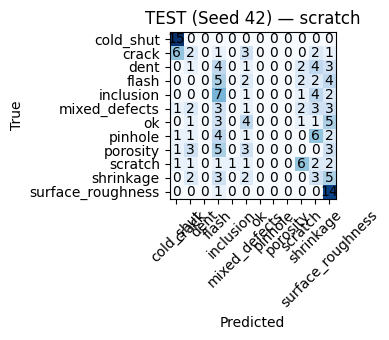

Loaded weights for baseline from resnet18_seed_42.pt
TEST (Seed 42) — baseline
                   precision    recall  f1-score   support

        cold_shut     1.0000    1.0000    1.0000        15
            crack     0.8750    0.9333    0.9032        15
             dent     0.8667    0.8667    0.8667        15
            flash     0.3333    0.2000    0.2500        15
        inclusion     0.9333    0.9333    0.9333        15
    mixed_defects     1.0000    0.8000    0.8889        15
               ok     0.3500    0.4667    0.4000        15
          pinhole     0.8824    1.0000    0.9375        15
         porosity     0.8125    0.8667    0.8387        15
          scratch     0.9091    0.6667    0.7692        15
        shrinkage     1.0000    0.9333    0.9655        15
surface_roughness     0.7500    1.0000    0.8571        15

         accuracy                         0.8056       180
        macro avg     0.8094    0.8056    0.8009       180
     weighted avg     0.8094    0.

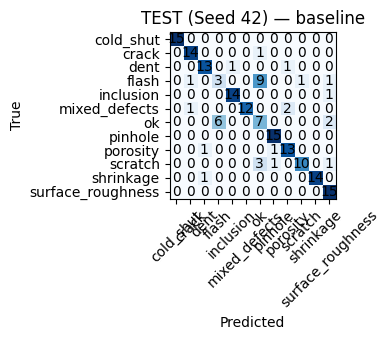

Loaded weights for class_weights from resnet18_cw_seed_42.pt
TEST (Seed 42) — class_weights
                   precision    recall  f1-score   support

        cold_shut     1.0000    1.0000    1.0000        15
            crack     0.8667    0.8667    0.8667        15
             dent     0.7368    0.9333    0.8235        15
            flash     0.4000    0.2667    0.3200        15
        inclusion     1.0000    0.8667    0.9286        15
    mixed_defects     0.9231    0.8000    0.8571        15
               ok     0.4444    0.5333    0.4848        15
          pinhole     0.8750    0.9333    0.9032        15
         porosity     0.8750    0.9333    0.9032        15
          scratch     0.8571    0.8000    0.8276        15
        shrinkage     0.9167    0.7333    0.8148        15
surface_roughness     0.7895    1.0000    0.8824        15

         accuracy                         0.8056       180
        macro avg     0.8070    0.8056    0.8010       180
     weighted avg    

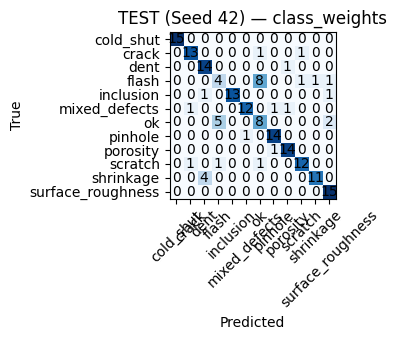

Loaded weights for gan_augmented from resnet18_gan_seed_42.pt
TEST (Seed 42) — gan_augmented
                   precision    recall  f1-score   support

        cold_shut     1.0000    1.0000    1.0000        15
            crack     0.7778    0.9333    0.8485        15
             dent     0.8571    0.8000    0.8276        15
            flash     0.5000    0.3333    0.4000        15
        inclusion     0.9333    0.9333    0.9333        15
    mixed_defects     1.0000    0.6667    0.8000        15
               ok     0.4091    0.6000    0.4865        15
          pinhole     1.0000    1.0000    1.0000        15
         porosity     0.7368    0.9333    0.8235        15
          scratch     0.8889    0.5333    0.6667        15
        shrinkage     1.0000    0.8667    0.9286        15
surface_roughness     0.7500    1.0000    0.8571        15

         accuracy                         0.8000       180
        macro avg     0.8211    0.8000    0.7977       180
     weighted avg   

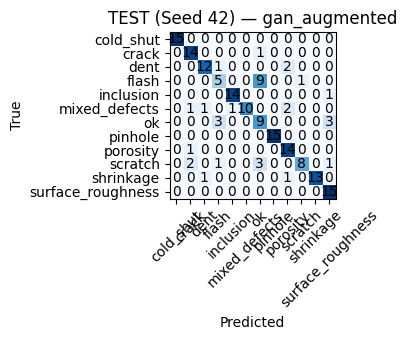

,macro_f1,minority_recall,minority_precision,minority_pr_auc,accuracy
scratch,0.1813,0.0000,0.0000,0.0947,0.2556
baseline,0.8009,0.8667,0.8667,0.9319,0.8056
class_weights,0.8010,0.9333,0.7368,0.9371,0.8056
gan_augmented,0.7977,0.8000,0.8571,0.9551,0.8000


In [12]:
# === Final Evaluation Stage ===
# This section evaluates our final models on the completely untouched real test images.

import numpy as np
import pandas as pd
import json
import random
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from sklearn.metrics import classification_report, confusion_matrix, f1_score, recall_score, precision_score, average_precision_score
from PIL import Image
from pathlib import Path
import matplotlib.pyplot as plt

# Self-contained setup variables
OUT = Path("/content/drive/MyDrive/DL_CA3_Dataset/outputs_option_a")
DATA_ROOT = Path("/content/drive/MyDrive/DL_CA3_Dataset/defect_dataset")
MINORITY = "dent"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
USE_PRETRAINED = True
IMG_SIZE = 224
BATCH_SIZE = 32

# Safely load the exact saved Seed 42 test split
test_split_path = OUT / "seed_42_test_split.json"
if test_split_path.exists():
    with open(test_split_path, "r") as f:
        split_data = json.load(f)
    CLASSES = split_data["classes"]
    test_items_42 = split_data["test_items"]
    print(f"Successfully loaded exact Seed 42 test split containing {len(test_items_42)} images.")

    # Strict Validation Checks
    # 1. Compare the saved classes with the actual sorted class directories in DATA_ROOT
    actual_classes = sorted(d.name for d in Path(DATA_ROOT).iterdir() if d.is_dir())
    if CLASSES != actual_classes:
        raise ValueError(f"Class mismatch! Saved: {CLASSES}, Actual: {actual_classes}")

    # 2. Validate that every saved image path exists on disk, and parent directory matches its label
    for path_str, label_idx in test_items_42:
        img_path = Path(path_str)
        if not img_path.exists():
            raise ValueError(f"Missing image path! File does not exist on disk: {path_str}")

        expected_class_name = CLASSES[label_idx]
        actual_parent_name = img_path.parent.name
        if expected_class_name != actual_parent_name:
            raise ValueError(
                f"Label alignment mismatch! Image parent folder '{actual_parent_name}' "
                f"does not match expected class '{expected_class_name}' for label index {label_idx} in: {path_str}"
            )

    print("Validation passed: All saved test image paths exist on disk, match parent folders, and align with dataset classes.")
else:
    raise FileNotFoundError("Exact Seed 42 split file not found. Please run active Cell 32 first.")

MIN_IDX = CLASSES.index(MINORITY)
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

class ImageListDataset(Dataset):
    def __init__(self, items, tf):
        self.items, self.tf = items, tf
    def __len__(self):
        return len(self.items)
    def __getitem__(self, i):
        p, y = self.items[i]
        return self.tf(Image.open(p).convert("RGB")), y

def loader(items, tf, shuffle):
    return DataLoader(ImageListDataset(items, tf), batch_size=BATCH_SIZE, shuffle=shuffle, num_workers=2)

test_loader_42 = loader(test_items_42, eval_tf, False)

class SmallCNN(nn.Module):
    def __init__(self, n_classes):
        super().__init__()
        def block(i, o):
            return nn.Sequential(
                nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(),
                nn.Conv2d(o, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(),
                nn.MaxPool2d(2)
            )
        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128), block(128, 256))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(256, n_classes))
    def forward(self, x):
        return self.head(self.features(x))

def build_model(name):
    if name == "scratch":
        return SmallCNN(len(CLASSES))
    m = models.resnet18(weights="DEFAULT" if USE_PRETRAINED else None)
    m.fc = nn.Linear(m.fc.in_features, len(CLASSES))
    return m

@torch.no_grad()
def predict(model, dl):
    model.eval()
    ys, probs, loss_sum = [], [], 0.0
    for x, y in dl:
        out = model(x.to(DEVICE)).cpu()
        loss_sum += F.cross_entropy(out, y, reduction="sum").item()
        ys.append(y); probs.append(out.softmax(1))
    y, p = torch.cat(ys).numpy(), torch.cat(probs).numpy()
    return y, p.argmax(1), p, loss_sum / len(y)

def summarise(y, yp, prob):
    onehot = np.eye(len(CLASSES))[y]
    return {
        "macro_f1": f1_score(y, yp, average="macro", zero_division=0),
        "minority_recall": recall_score(y, yp, labels=[MIN_IDX], average="macro", zero_division=0),
        "minority_precision": precision_score(y, yp, labels=[MIN_IDX], average="macro", zero_division=0),
        "minority_pr_auc": average_precision_score(onehot[:, MIN_IDX], prob[:, MIN_IDX]),
        "accuracy": float((y == yp).mean())
    }

def full_report(y, yp, title):
    print(title); print(classification_report(y, yp, target_names=CLASSES, digits=4, zero_division=0))
    cm = confusion_matrix(y, yp)
    fig, ax = plt.subplots(figsize=(4, 3.5)); ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(len(CLASSES)), CLASSES, rotation=45); ax.set_yticks(range(len(CLASSES)), CLASSES)
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)): ax.text(j, i, cm[i, j], ha="center", va="center")
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(title); plt.tight_layout(); plt.show()

# Initialize and load model configurations
final_models = {
    "scratch": build_model("scratch").to(DEVICE),
    "baseline": build_model("resnet18").to(DEVICE),
    "class_weights": build_model("resnet18").to(DEVICE),
    "gan_augmented": build_model("resnet18").to(DEVICE)
}

model_checkpoints = {
    "scratch": OUT / "scratch_seed_42.pt",
    "baseline": OUT / "resnet18_seed_42.pt",
    "class_weights": OUT / "resnet18_cw_seed_42.pt",
    "gan_augmented": OUT / "resnet18_gan_seed_42.pt"
}

test_rows = {}
for name, model in final_models.items():
    ckpt = model_checkpoints[name]
    if ckpt.exists():
        model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
        print(f"Loaded weights for {name} from {ckpt.name}")
        y, yp, p, _ = predict(model, test_loader_42)
        test_rows[name] = summarise(y, yp, p)
        full_report(y, yp, f"TEST (Seed 42) — {name}")
    else:
        print(f"Checkpoint {ckpt.name} not found. Please run the multi-seed experiment cell first.")

if test_rows:
    test_table = pd.DataFrame(test_rows).T.round(4)
    test_table.to_csv(OUT / "test_results.csv")
    display(test_table)

## 9. Explainability with Grad-CAM

Grad-CAM produces a class-discriminative heatmap from the last convolutional layer. For a target class $c$, the gradients of the class score $y^c$ with respect to the feature maps $A^k$ are averaged to give channel weights

$$\alpha_k^c = \frac{1}{Z}\sum_{i,j} \frac{\partial y^c}{\partial A^k_{ij}}, \qquad L^c_{\text{Grad-CAM}} = \mathrm{ReLU}\Big(\sum_k \alpha_k^c A^k\Big).$$

The map is upsampled to the input size and overlaid on the image. It indicates which regions increased the score of the predicted class. Examine both correct and incorrect predictions, and determine whether the model relies on the defect itself or on spurious cues such as background, lighting or borders.

Successfully loaded exact Seed 42 test split containing 180 images for Grad-CAM.
Validation passed: All saved test image paths exist on disk, match parent folders, and align with dataset classes.
Loaded final GAN-augmented model checkpoint successfully.


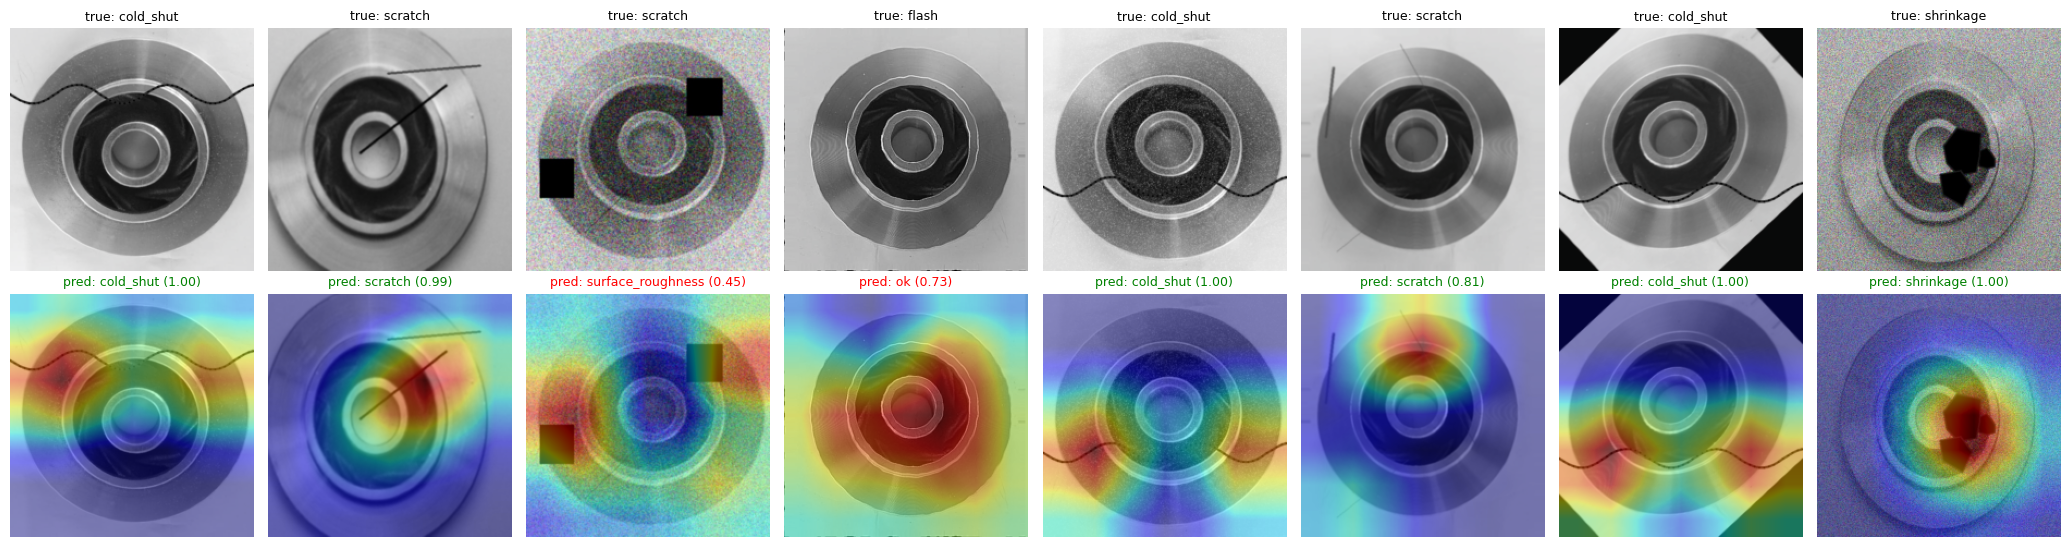

In [13]:
import numpy as np
import matplotlib.pyplot as plt
import json
import random
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.model_selection import train_test_split
from pathlib import Path
from PIL import Image
from torchvision import models, transforms
from torch.utils.data import Dataset as TorchDataset

# --- 1. Unconditional Configuration & Setup ---
OUT = Path("/content/drive/MyDrive/DL_CA3_Dataset/outputs_option_a")
DATA_ROOT = Path("/content/drive/MyDrive/DL_CA3_Dataset/defect_dataset")
MINORITY = "dent"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
USE_PRETRAINED = True
IMG_SIZE = 224

# Ensure output directories exist
OUT.mkdir(parents=True, exist_ok=True)

# Safely load the exact saved Seed 42 test split
test_split_path = OUT / "seed_42_test_split.json"
if test_split_path.exists():
    with open(test_split_path, "r") as f:
        split_data = json.load(f)
    CLASSES = split_data["classes"]
    test_items_42 = split_data["test_items"]
    print(f"Successfully loaded exact Seed 42 test split containing {len(test_items_42)} images for Grad-CAM.")

    # Strict Validation Checks
    # 1. Compare the saved classes with the actual sorted class directories in DATA_ROOT
    actual_classes = sorted(d.name for d in Path(DATA_ROOT).iterdir() if d.is_dir())
    if CLASSES != actual_classes:
        raise ValueError(f"Class mismatch! Saved: {CLASSES}, Actual: {actual_classes}")

    # 2. Validate that every saved image path exists on disk, and parent directory matches its label
    for path_str, label_idx in test_items_42:
        img_path = Path(path_str)
        if not img_path.exists():
            raise ValueError(f"Missing image path! File does not exist on disk: {path_str}")

        expected_class_name = CLASSES[label_idx]
        actual_parent_name = img_path.parent.name
        if expected_class_name != actual_parent_name:
            raise ValueError(
                f"Label alignment mismatch! Image parent folder '{actual_parent_name}' "
                f"does not match expected class '{expected_class_name}' for label index {label_idx} in: {path_str}"
            )

    print("Validation passed: All saved test image paths exist on disk, match parent folders, and align with dataset classes.")
else:
    raise FileNotFoundError("Exact Seed 42 split file not found. Please run active Cell 32 first.")

MIN_IDX = CLASSES.index(MINORITY) if MINORITY in CLASSES else 2

# --- 2. Architecture & Dataset Helper Definitions ---
class SmallCNN(nn.Module):
    def __init__(self, n_classes):
        super().__init__()
        def block(i, o):
            return nn.Sequential(
                nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(),
                nn.Conv2d(o, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(),
                nn.MaxPool2d(2)
            )
        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128), block(128, 256))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(256, n_classes))
    def forward(self, x):
        return self.head(self.features(x))

def build_model(name):
    if name == "scratch":
        return SmallCNN(len(CLASSES))
    m = models.resnet18(weights="DEFAULT" if USE_PRETRAINED else None)
    m.fc = nn.Linear(m.fc.in_features, len(CLASSES))
    return m

def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

class ImageListDataset(TorchDataset):
    def __init__(self, items, tf):
        self.items = items
        self.tf = tf
    def __len__(self):
        return len(self.items)
    def __getitem__(self, i):
        p, y = self.items[i]
        return self.tf(Image.open(p).convert("RGB")), y

MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

# --- 3. Grad-CAM Class implementation ---
class GradCAM:
    def __init__(self, model, layer):
        self.model = model
        self.acts = None
        self.grads = None
        layer.register_forward_hook(lambda m, i, o: setattr(self, "acts", o.detach()))
        layer.register_full_backward_hook(lambda m, gi, go: setattr(self, "grads", go[0].detach()))
    def __call__(self, x):
        self.model.eval()
        x = x.clone().requires_grad_(True)
        out = self.model(x); c = out.argmax(1).item()
        self.model.zero_grad(); out[0, c].backward()
        w = self.grads.mean(dim=(2, 3), keepdim=True)
        cam = F.relu((w * self.acts).sum(1, keepdim=True))
        cam = F.interpolate(cam, size=x.shape[2:], mode="bilinear", align_corners=False)[0, 0]
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam.cpu().numpy(), c, out.softmax(1)[0, c].item()

# --- 4. Execution Logic ---
final_model = build_model("resnet18").to(DEVICE)
gan_augmented_ckpt = OUT / "resnet18_gan_seed_42.pt"

if gan_augmented_ckpt.exists() and len(test_items_42) > 0:
    final_model.load_state_dict(torch.load(gan_augmented_ckpt, map_location=DEVICE))
    print("Loaded final GAN-augmented model checkpoint successfully.")

    layer = final_model.layer4[-1] if hasattr(final_model, "layer4") else final_model.features[-1]
    cam = GradCAM(final_model, layer)

    set_seed(42)
    test_ds = ImageListDataset(test_items_42, eval_tf)
    sel = np.random.default_rng(0).choice(len(test_ds), size=min(8, len(test_ds)), replace=False)

    fig, axes = plt.subplots(2, len(sel), figsize=(2.6 * len(sel), 5.6))
    axes = np.array(axes).reshape(2, -1)
    for k, i in enumerate(sel):
        x, y = test_ds[i]
        heat, pred, conf = cam(x.unsqueeze(0).to(DEVICE))
        img = np.clip(x.permute(1, 2, 0).numpy() * STD + MEAN, 0, 1)
        axes[0, k].imshow(img); axes[0, k].set_title(f"true: {CLASSES[y]}", fontsize=9)
        axes[1, k].imshow(img); axes[1, k].imshow(heat, cmap="jet", alpha=0.45)
        axes[1, k].set_title(f"pred: {CLASSES[pred]} ({conf:.2f})", fontsize=9, color="green" if pred == y else "red")
        axes[0, k].axis("off"); axes[1, k].axis("off")
    plt.tight_layout()
    plt.savefig(OUT / "gradcam.png", dpi=120)
    plt.show()
else:
    print("Checkpoint or valid test items not found. Please complete training in Cell 32 first.")

## 10. Required analysis for the technical report

1. **Framing:** domain, the cost of a missed defect versus a false alarm, and the success criterion stated in the proposal.
2. **Data:** class counts per split, the controlled minority ratio, augmentation choices and their justification, and the measures taken against leakage.
3. **Stage 1:** from-scratch versus pretrained comparison with training curves; diagnosis of any overfitting or instability and the remedy applied.
4. **Stage 2:** GAN loss curves, uncurated samples, any mode collapse observed; comparison of baseline, class weights and GAN augmentation on minority recall, precision, F1 and PR-AUC, with mean ± standard deviation across seeds.
5. **Conclusion on augmentation:** whether GAN augmentation improved minority-class recall on the real test set, and why. A negative result, properly diagnosed, is an acceptable finding.
6. **Grad-CAM:** at least eight test examples including errors; what the model attends to; whether the explanations would be trusted by a domain expert.
7. **Limitations:** dataset size, domain shift, threshold choice, and the conditions under which the system should not be deployed.

**Extensions:** conditional GAN (class-conditioned generator), Fréchet Inception Distance between real and synthetic images, decision-threshold tuning on validation for a target recall, EfficientNet-B0 as an additional backbone.

In [14]:
# This downloads the complete output folder as one ZIP, including checkpoints, CSV files, GAN histories and Grad-CAM image.
import os
import shutil
from google.colab import files
from pathlib import Path

OUTPUT_DIR = Path("/content/drive/MyDrive/DL_CA3_Dataset/outputs_option_a")

ZIP_PATH = "/content/Option_A_Trained_Models_and_Results.zip"

shutil.make_archive(
    ZIP_PATH.replace(".zip", ""),
    "zip",
    root_dir=OUTPUT_DIR
)

files.download(ZIP_PATH)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:
# Download Grad-CAM separately (gradcam.png)
from google.colab import files

files.download("/content/drive/MyDrive/DL_CA3_Dataset/outputs_option_a/gradcam.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:
# Verify that everything is saved
# This displays the saved files and their sizes.
from pathlib import Path

OUTPUT_DIR = Path("/content/drive/MyDrive/DL_CA3_Dataset/outputs_option_a")

for file in sorted(OUTPUT_DIR.rglob("*")):
    if file.is_file():
        size_mb = file.stat().st_size / (1024 * 1024)
        print(f"{file.name:45} {size_mb:.2f} MB")

gan_checkpoint_seed_101.pt                    72.63 MB
gan_checkpoint_seed_2023.pt                   72.63 MB
gan_checkpoint_seed_42.pt                     72.63 MB
gan_grid_seed_42_epoch_100.png                0.16 MB
gan_grid_seed_42_epoch_150.png                0.16 MB
gan_grid_seed_42_epoch_200.png                0.16 MB
gan_grid_seed_42_epoch_250.png                0.15 MB
gan_grid_seed_42_epoch_300.png                0.15 MB
gan_grid_seed_42_epoch_50.png                 0.17 MB
gan_history_seed_101.json                     0.02 MB
gan_history_seed_2023.json                    0.02 MB
gan_history_seed_42.json                      0.02 MB
generator.pt                                  13.66 MB
gradcam.png                                   1.69 MB
multi_seed_results.csv                        0.00 MB
multi_seed_results_raw.csv                    0.00 MB
resnet18.pt                                   42.73 MB
resnet18_classweights.pt                      42.73 MB
resnet18_classweights_

In [18]:
from pathlib import Path
import shutil

SOURCE = Path("/content/drive/MyDrive/DL_CA3_Dataset/outputs_option_a")

DEST = Path("/content/drive/MyDrive/CA 3_Capstone_Project/CSD402_CA3_Submission/GAN_Artifacts")

CHECKPOINTS = DEST / "GAN_Checkpoints"
HISTORY = DEST / "GAN_History"

CHECKPOINTS.mkdir(parents=True, exist_ok=True)
HISTORY.mkdir(parents=True, exist_ok=True)

# Copy GAN checkpoints
for f in SOURCE.glob("gan_checkpoint_seed_*.pt"):
    shutil.copy2(f, CHECKPOINTS / f.name)

# Copy GAN training histories
for f in SOURCE.glob("gan_history_seed_*.json"):
    shutil.copy2(f, HISTORY / f.name)

print("GAN artifacts organized successfully!")

GAN artifacts organized successfully!


In [19]:
for folder in [CHECKPOINTS, HISTORY]:
    print(f"\n{folder.name}:")
    for f in sorted(folder.iterdir()):
        print(f"  {f.name} - {f.stat().st_size / (1024*1024):.2f} MB")


GAN_Checkpoints:
  gan_checkpoint_seed_101.pt - 72.63 MB
  gan_checkpoint_seed_2023.pt - 72.63 MB
  gan_checkpoint_seed_42.pt - 72.63 MB

GAN_History:
  gan_history_seed_101.json - 0.02 MB
  gan_history_seed_2023.json - 0.02 MB
  gan_history_seed_42.json - 0.02 MB
